In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
# Loading the dataset
df = pd.read_csv('data/SMSSpamCollection', sep='\t', header=None, names=['label', 'message'])

In [6]:
df.shape

(5572, 2)

In [7]:
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [8]:
df.columns

Index(['label', 'message'], dtype='object')

In [9]:
df.dtypes

label      object
message    object
dtype: object

In [10]:
df.isna().sum()

label      0
message    0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(403)

In [12]:
df['label'].value_counts()

label
ham     4825
spam     747
Name: count, dtype: int64

In [13]:
(df['label'].value_counts(normalize=True)*100).round(2)

label
ham     86.59
spam    13.41
Name: proportion, dtype: float64

In [15]:
df['char_count'] = df['message'].str.len()
df['word_count'] = df['message'].str.split().str.len()

In [17]:
df['char_count'].describe()

count    5572.000000
mean       80.489950
std        59.942907
min         2.000000
25%        36.000000
50%        62.000000
75%       122.000000
max       910.000000
Name: char_count, dtype: float64

In [18]:
df['word_count'].describe()

count    5572.000000
mean       15.597452
std        11.404053
min         1.000000
25%         7.000000
50%        12.000000
75%        23.000000
max       171.000000
Name: word_count, dtype: float64

In [16]:
df.groupby('label')[['char_count', 'word_count']].mean().round(2)

,char_count,word_count
label,,
ham,71.48,14.31
spam,138.67,23.91


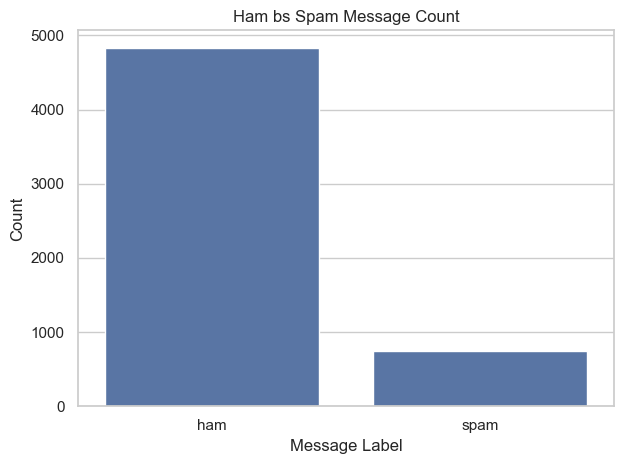

In [19]:
sns.set_theme(style='whitegrid')
plt.Figure(figsize=(6,4))
sns.countplot(data=df, x='label')
plt.title("Ham bs Spam Message Count")
plt.xlabel("Message Label")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

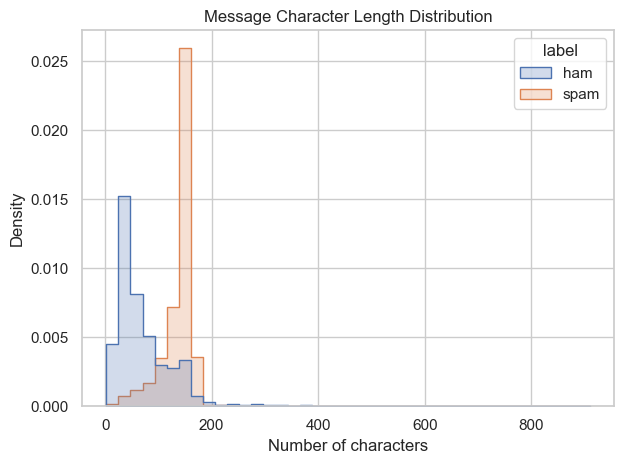

In [20]:
plt.Figure(figsize=(8,5))
sns.histplot(data=df, x='char_count', hue='label', bins=40, element='step', stat='density', common_norm=False)
plt.title('Message Character Length Distribution')
plt.xlabel('Number of characters')
plt.tight_layout()
plt.show()

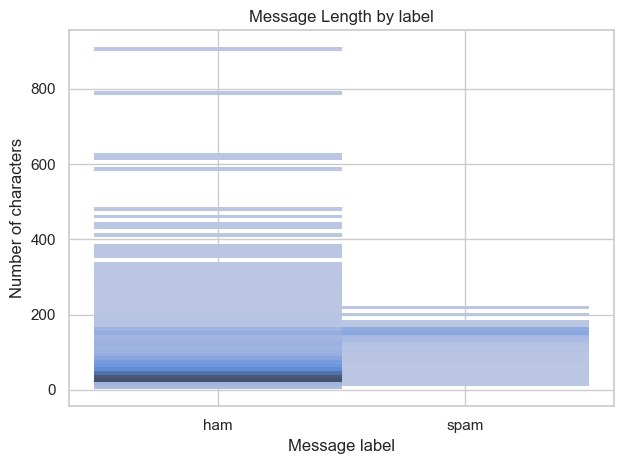

In [21]:
plt.Figure(figsize=(8,5))
sns.histplot(data=df, x='label', y='char_count')
plt.title('Message Length by label')
plt.xlabel('Message label')
plt.ylabel('Number of characters')
plt.tight_layout()
plt.show()

In [24]:
#removing the duplicate
df = df.drop_duplicates().reset_index(drop=True)

In [25]:
df.duplicated().sum()

np.int64(0)

In [26]:
df.shape

(5169, 4)

In [27]:
df.head(5)

,label,message,char_count,word_count
0,ham,"Go until jurong point, crazy.. Available only ...",111,20
1,ham,Ok lar... Joking wif u oni...,29,6
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155,28
3,ham,U dun say so early hor... U c already then say...,49,11
4,ham,"Nah I don't think he goes to usf, he lives aro...",61,13


In [28]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

In [29]:
X = df['message']
y = df['label']

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20, random_state=42, stratify=y)

In [60]:
#converting text into TFIDF features
tfidf = TfidfVectorizer(
    lowercase=True, ngram_range=(1,2), min_df=2
)

In [61]:
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [62]:
X_train.shape[0]

4135

In [63]:
X_test.shape[0]

1034

In [64]:
X_train_tfidf.shape

(4135, 10188)

In [65]:
X_test_tfidf.shape

(1034, 10188)

In [66]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)

In [67]:
model_nb = MultinomialNB()
model_nb.fit(X_train_tfidf, y_train)

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


In [68]:
y_pred = model_nb.predict(X_test_tfidf)

In [69]:
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

Accuracy: 0.9623


In [70]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       903
        spam       1.00      0.70      0.83       131

    accuracy                           0.96      1034
   macro avg       0.98      0.85      0.90      1034
weighted avg       0.96      0.96      0.96      1034



In [71]:
cm = confusion_matrix(y_test, y_pred, labels=['ham', 'spam'])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['ham', 'spam']
)

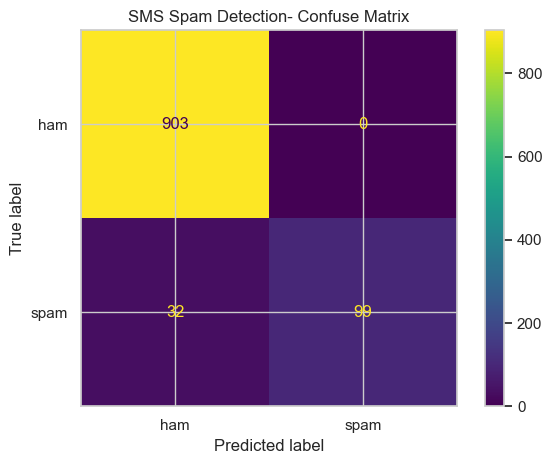

In [51]:
disp.plot()
plt.title("SMS Spam Detection- Confuse Matrix")
plt.tight_layout()
plt.show()

In [52]:
from sklearn.linear_model import LogisticRegression

In [72]:
model_lr = LogisticRegression(C=2.0, max_iter=1000)
model_lr.fit(X_train_tfidf, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,2.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [73]:
y_pred_lr = model_lr.predict(X_test_tfidf)

In [74]:
round(accuracy_score(y_test, y_pred_lr),2)

0.97

In [75]:
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       903
        spam       0.98      0.79      0.87       131

    accuracy                           0.97      1034
   macro avg       0.98      0.89      0.93      1034
weighted avg       0.97      0.97      0.97      1034



In [76]:
errors = X_test[
    (y_test == 'spam') & (y_pred == 'ham')
]

print(f"Missed spam messages: {len(errors)}")
display(errors.to_frame(name='message').head(15))

Missed spam messages: 39


,message
1459,Thanks for the Vote. Now sing along with the s...
5137,Want explicit SEX in 30 secs? Ring 02073162414...
521,You will recieve your tone within the next 24h...
2697,Send a logo 2 ur lover - 2 names joined by a h...
2908,"Hi babe its Jordan, how r u? Im home from abro..."
1611,Hi if ur lookin 4 saucy daytime fun wiv busty ...
4752,TheMob>Hit the link to get a premium Pink Pant...
1893,Guess what! Somebody you know secretly fancies...
5139,ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE ...
4365,Customer service announcement. We recently tri...


In [77]:
spam_index = list(model_lr.classes_).index('spam')
spam_prob = model_lr.predict_proba(X_test_tfidf)[:, spam_index]
print(spam_prob[:10])

[0.02266073 0.01755785 0.05527832 0.0687198  0.01354485 0.06757323
 0.04835851 0.00615135 0.03377912 0.03687063]


In [81]:
import pickle

with open('models/spam_model.pkl', 'wb') as f:
    pickle.dump(model_lr, f)
with open('models/tfidf_vectorizer.pkl', 'wb') as f:
    pickle.dump(tfidf, f)
